<a href="https://colab.research.google.com/github/karthick-2008/DSA0404-Fundamental-Of-Data-Science/blob/main/Q.NO_39.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving 39.xlsx to 39.xlsx
CUSTOMER SEGMENTATION RESULTS
--------------------------------
   Customer_ID  Total_Amount_Spent  Items_Purchased  Cluster
0      SHP-001               99.83                2        2
1      SHP-002               78.72                1        2
2      SHP-003              114.21                1        2
3      SHP-004               79.39                1        2
4      SHP-005               17.51                2        2
..         ...                 ...              ...      ...
65     SHP-066             1047.77               13        1
66     SHP-067              825.11               19        1
67     SHP-068              834.02               16        1
68     SHP-069             1264.86               26        1
69     SHP-070              933.64               19        1

[70 rows x 4 columns]

Number of Customers in Each Cluster:
Cluster
0    25
1    19
2    26
Name: count, dtype: int64

Cluster Summary:
         Total_Amount_Spent  Items_Purchas

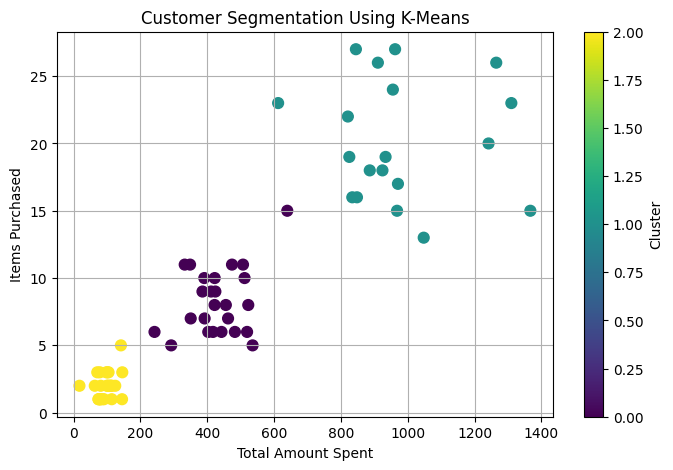

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from google.colab import files

# Upload dataset
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Read Excel dataset
df = pd.read_excel(filename)

# Select features
X = df[['Total_Amount_Spent', 'Items_Purchased']]

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Display customer clusters
print("CUSTOMER SEGMENTATION RESULTS")
print("--------------------------------")
print(df[['Customer_ID', 'Total_Amount_Spent',
          'Items_Purchased', 'Cluster']])

# Count customers in each cluster
print("\nNumber of Customers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

# Cluster summary
print("\nCluster Summary:")
print(df.groupby('Cluster')[
    ['Total_Amount_Spent', 'Items_Purchased']
].mean().round(2))

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(
    df['Total_Amount_Spent'],
    df['Items_Purchased'],
    c=df['Cluster'],
    cmap='viridis',
    s=60
)

plt.xlabel('Total Amount Spent')
plt.ylabel('Items Purchased')
plt.title('Customer Segmentation Using K-Means')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

# Save results
df.to_excel('Customer_Segmentation_Result.xlsx', index=False)
files.download('Customer_Segmentation_Result.xlsx')
